## Compare complexity measures

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

In [10]:
real = pd.read_csv('../results/synthetic_stage1.csv')
stage1 = pd.read_csv('../results/synthetic_stage1.csv')
stage2 = pd.read_csv('../results/synthetic_stage1.csv')
stage3 = pd.read_csv('../results/synthetic_stage1.csv')

In [16]:
def barplot(df, base):
    fig, axes = plt.subplots(1, 3, figsize=(12, 2.8))
    for ax, col in zip(axes, df.columns[1:4]):
        if col not in df:
            ax.set_visible(False); continue
        v = df[col]
        ax.hist(v, bins=30, linewidth=1)
        ax.set_title(col)
        ax.grid(axis="x", visible=False)
    fig.suptitle(f'Características dos datasets {base}', x=0.01, ha="left")
    fig.tight_layout()
    plt.show()

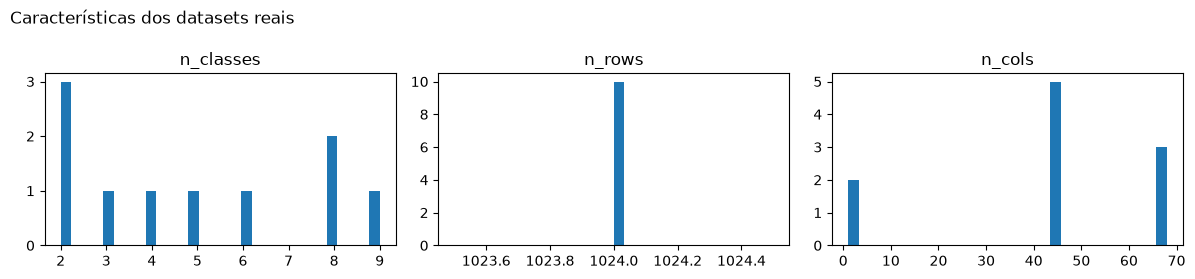

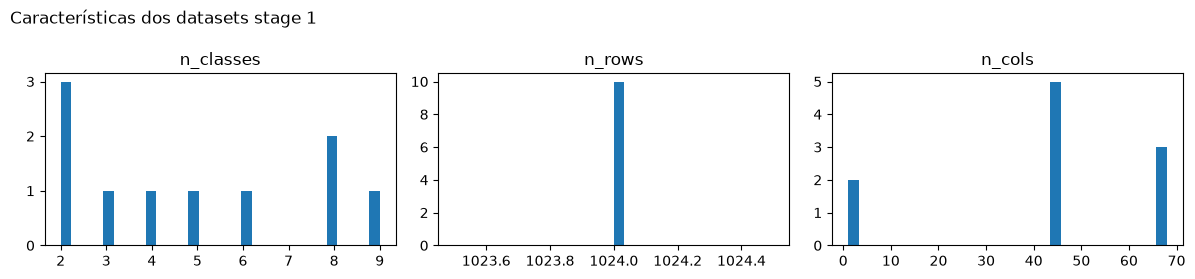

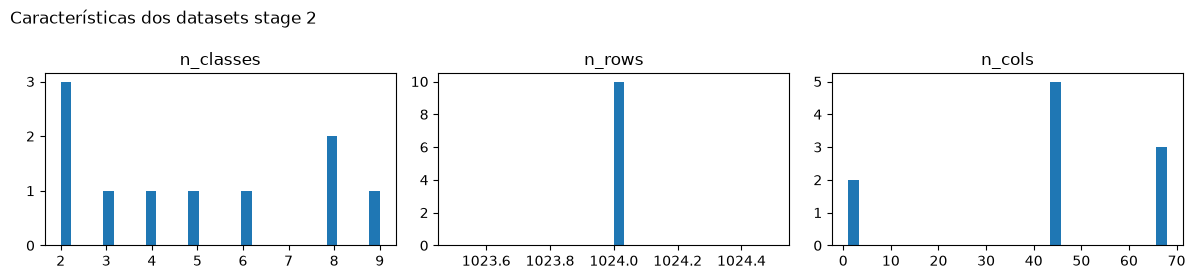

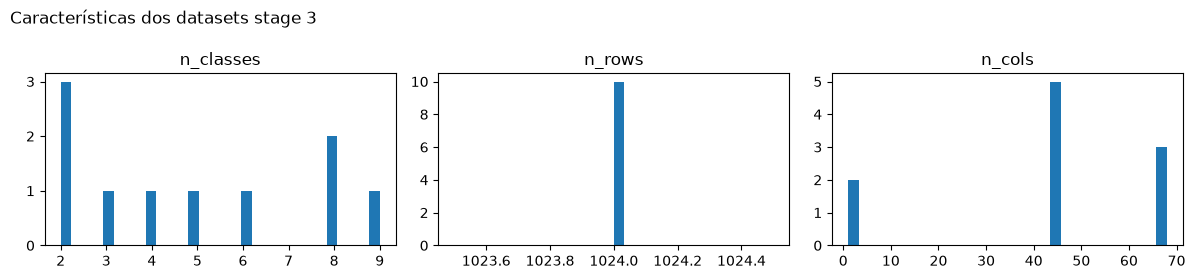

In [17]:
barplot(real, 'reais'); barplot(stage1, 'stage 1'); barplot(stage2, 'stage 2'); barplot(stage3, 'stage 3')

In [18]:
def boxplot(df, base):
    meta = ["id", "n_classes", "n_rows", "n_cols"]
    medidas = df.drop(columns=meta).dropna(axis="columns", how="all")
    variaveis = medidas.median().sort_values().index.tolist()
    
    fig, ax = plt.subplots(figsize=(max(8, 0.55 * len(variaveis)), 4))
    ax.boxplot([medidas[c].dropna() for c in variaveis])
    ax.set_xticks(
        range(1, len(variaveis) + 1), variaveis,
        rotation=60, ha="right", rotation_mode="anchor",
    )
    ax.set_ylabel("valor da medida")
    ax.set_title(f'Medidas de complexidade da base {base}')
    ax.grid(axis="x", visible=False)
    fig.tight_layout()
    plt.show()

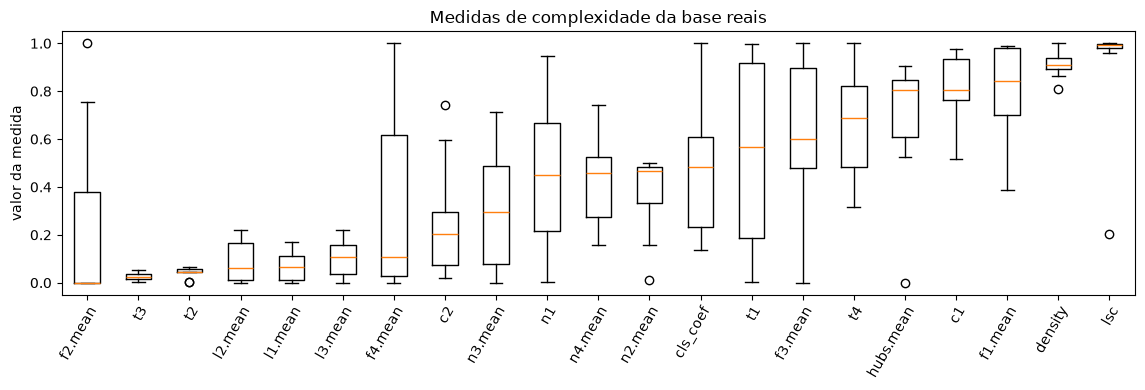

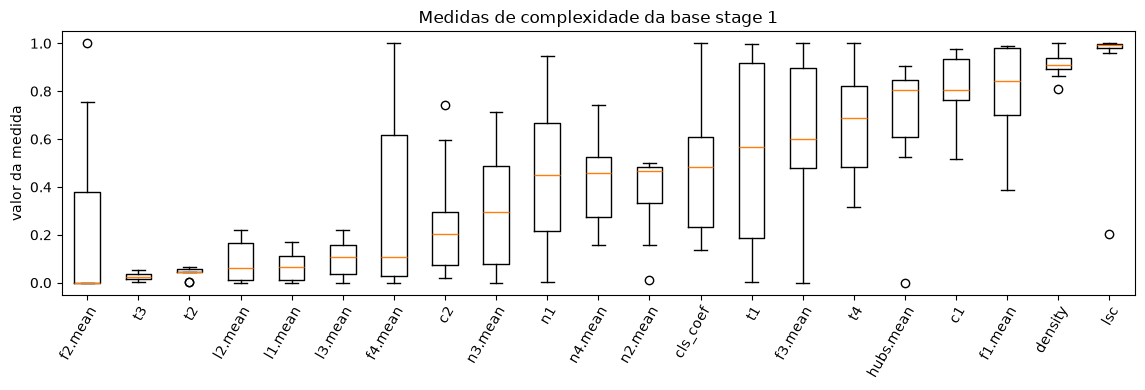

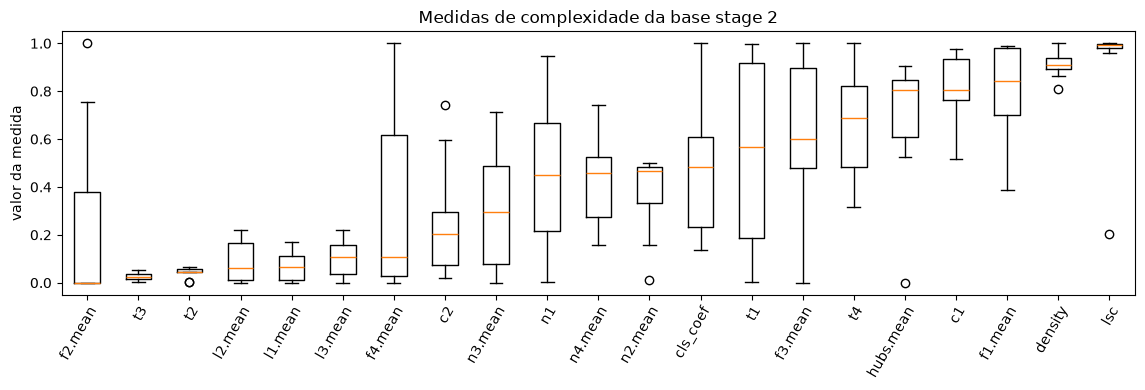

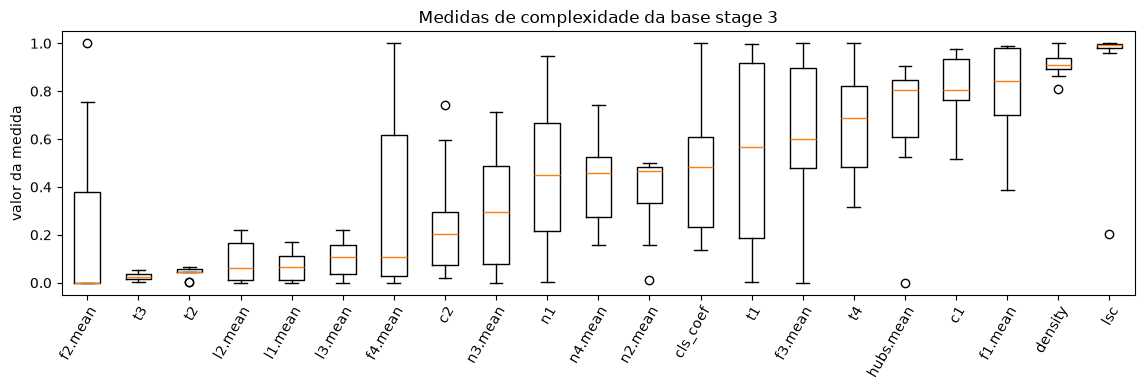

In [19]:
boxplot(real, 'reais'); boxplot(stage1, 'stage 1'); boxplot(stage2, 'stage 2'); boxplot(stage3, 'stage 3')

In [ ]:
cols_corr = df.iloc[:, 4:].dropna(axis="columns", how="all").columns
corr = df[cols_corr].corr(method="spearman")
n = len(cols_corr)
fig, ax = plt.subplots(figsize=(0.45 * n + 2.5, 0.45 * n + 1))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)     # azul = negativa, vermelho = positiva
ax.set_xticks(range(n), cols_corr, rotation=90)
ax.set_yticks(range(n), cols_corr)
ax.grid(False)
for i in range(n):
    for j in range(n):
        r = corr.iloc[i, j]
        if i != j and abs(r) >= 0.7:                          # anota só as correlações fortes
            ax.text(j, i, f"{r:.1f}", ha="center", va="center", fontsize=6,
                    color="white" if abs(r) > 0.75 else "black")
fig.colorbar(im, ax=ax, fraction=0.04, label="correlação de Spearman")
ax.set_title("Correlação entre medidas de complexidade (números: |ρ| ≥ 0.7)")
fig.tight_layout(); plt.show()

In [ ]:
# Próximos passos
# - rodar na axia
# - usar o prior do tabicl v2
# - definir os hyperparametros de geração das bases
# - rodar as medias de complexidade para bases reais
# - vamos gerar dados siteticos?

# Mais comentarios
# - mais meta-features como impureza de gini (arvore)
# - usar classificadores como metricas
# - 